# Ramen on DomainNet: evaluation and failure analysis

Runs **Ramen** and a **NoAdapt** baseline (zero-shot CLIP ViT-B/32) on exactly the same test stream, then breaks down where Ramen helps and where it fails. Same analysis as `cifar100c_ramen.ipynb`, on DomainNet: 6 domains (clipart, infograph, painting, quickdraw, real, sketch), 345 classes, ~596k images.
Differences from CIFAR-100-C: the environments are *domains*, each with different images and a different size, rather than corruptions of one shared test set. DomainNet also has no superclass grouping, so the class heatmaps are per class and there is no error-granularity section.
The code lives in `ramen_analysis.py` (`DomainNetExperiment`). Results are cached in `results/`, so you can re-run the plot cells without re-running the models.

In [1]:
%load_ext autoreload
%autoreload 2

import os
os.environ.setdefault('CUDA_VISIBLE_DEVICES', '1')  # pick a free GPU; must be set before torch is imported

import pandas as pd
from ramen_analysis import DomainNetExperiment

/home/priyank1/miniconda3/envs/RAMEN/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
exp = DomainNetExperiment(
    model='clip_vitbase32',
    tta_mode='mixed',      # 'mixed': one shuffled stream over all domains | 'single': each domain separately, reset between
    batch_size=100,
    n_per_domain=None,     # None = whole dataset (~596k images); e.g. 1000 for a quick run (random subset per domain)
    seed=0,
    num_workers=16,        # JPEG decoding is the bottleneck, unlike the in-memory CIFAR arrays
).load()

DomainNet: 6 domains x 596006 images in total, 345 classes, model=clip_vitbase32, mode=mixed


In [3]:
acc = exp.evaluate(capture_probs=True, capture_features=True)   # pass use_cache=False to force a re-run
acc

NoAdapt: loaded cached results from /home/priyank1/Projects/Ramen/new_experiments/results/DomainNet_clip_vitbase32_mixed_nall_bs100_s0_NoAdapt.pkl


Ramen: loaded cached results from /home/priyank1/Projects/Ramen/new_experiments/results/DomainNet_clip_vitbase32_mixed_nall_bs100_s0_Ramen.pkl


,NoAdapt,Ramen,delta
clipart,68.25,69.33,1.08
infograph,43.90,44.98,1.08
painting,64.58,65.70,1.12
quickdraw,13.33,17.54,4.21
real,82.12,82.27,0.15
sketch,60.05,60.96,0.91
average,55.37,56.80,1.43


## 1. Which domains does Ramen struggle on?
Orange = NoAdapt, blue = Ramen, so the line between them is what adaptation changes. Domains are sorted with Ramen's worst at the top. **Bold** numbers on the right are domains where Ramen does *worse* than doing nothing.

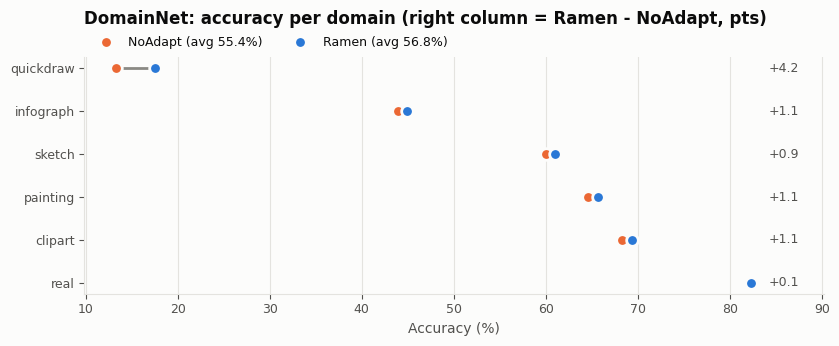

In [4]:
exp.plot_domain_accuracy();

## 2. Per-sample flips
The aggregate gain hides two opposing effects. Blue = samples Ramen **fixed** (NoAdapt wrong, Ramen right). Red = samples Ramen **broke** (NoAdapt right, Ramen wrong). A large red bar means harmful adaptation, even when the net gain is positive.

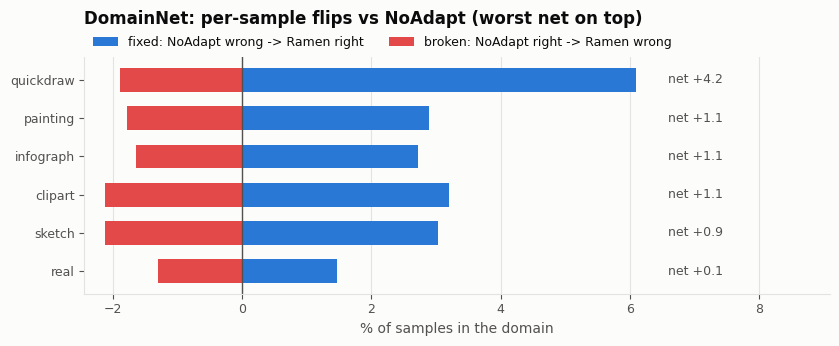

In [5]:
exp.plot_flips();

## 3. Which classes, under which domains?
Ramen − NoAdapt accuracy per class and domain, for the 30 classes Ramen hurts most on average (red = adaptation hurts). The second heatmap shows Ramen's absolute accuracy for the 30 classes where it is worst.

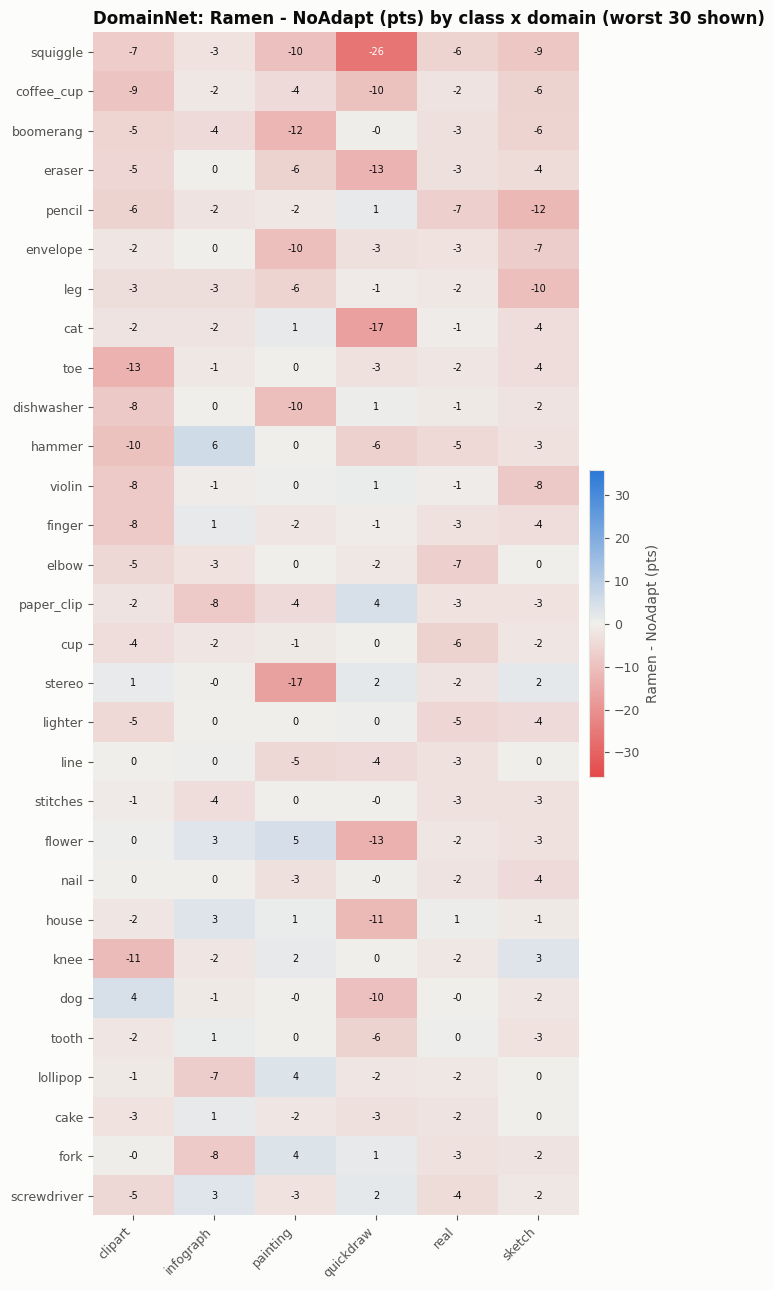

In [6]:
exp.plot_class_heatmap('delta', max_rows=30);

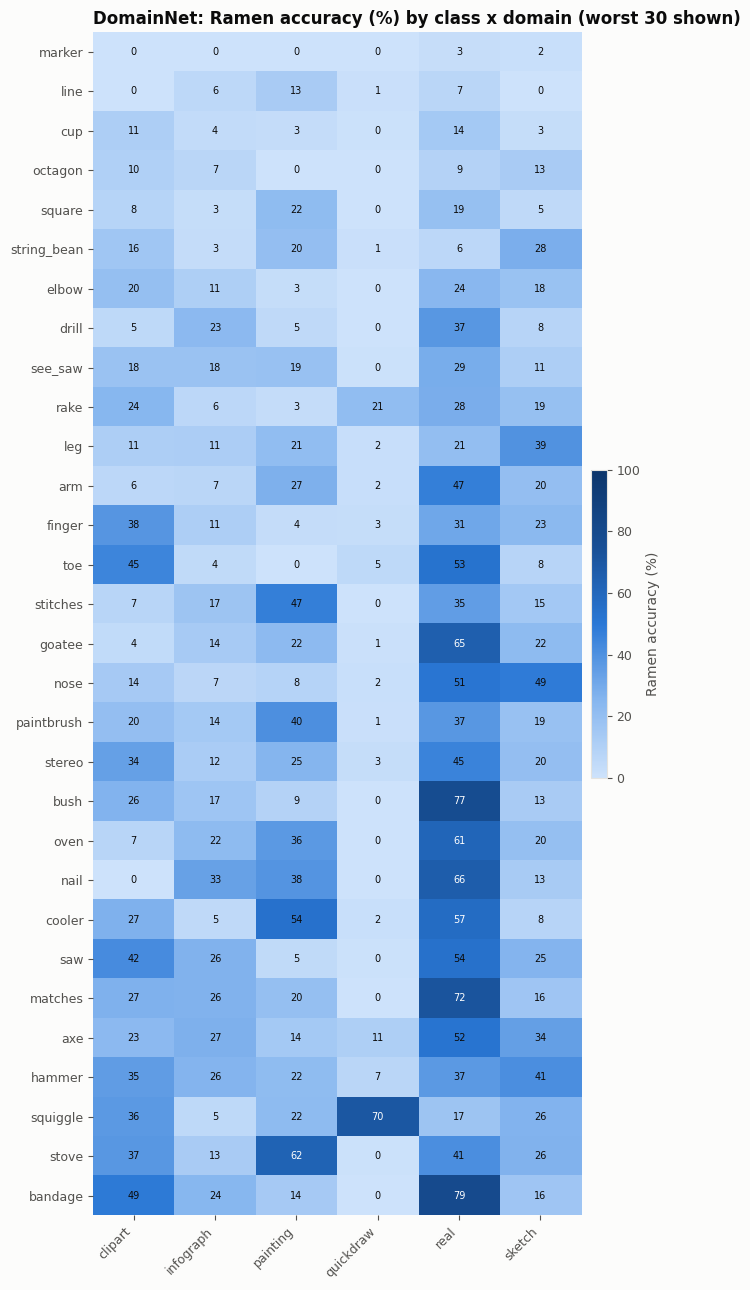

In [7]:
exp.plot_class_heatmap('Ramen', max_rows=30);

Per-class Ramen − NoAdapt accuracy over all domains, as a table: the classes adaptation hurts most and helps most.

In [8]:
r, b = exp.results['Ramen'], exp.results['NoAdapt']
per_class = pd.DataFrame({'NoAdapt': b.groupby('label')['correct'].mean() * 100,
                          'Ramen': r.groupby('label')['correct'].mean() * 100,
                          'samples': r.groupby('label').size()})
per_class['delta'] = per_class['Ramen'] - per_class['NoAdapt']
per_class.index = [exp.classes[i] for i in per_class.index]
per_class = per_class.sort_values('delta').round(2)
display(per_class.head(10))
per_class.tail(10)

,NoAdapt,Ramen,samples,delta
squiggle,48.10,35.13,1950,-12.97
eraser,40.69,32.94,1096,-7.76
coffee_cup,52.80,47.20,1909,-5.61
hammer,27.86,22.86,1181,-5.00
cat,71.34,66.50,1985,-4.84
envelope,74.86,70.53,1846,-4.33
line,10.21,6.58,1352,-3.62
elbow,15.39,12.16,1423,-3.23
house,62.52,59.47,1537,-3.06
toe,22.25,19.33,1438,-2.92


,NoAdapt,Ramen,samples,delta
underwear,54.26,61.74,1537,7.48
backpack,58.12,65.74,1798,7.62
ceiling_fan,49.66,57.86,878,8.20
basketball,64.35,73.30,1453,8.95
pillow,54.90,64.57,1736,9.68
washing_machine,50.26,59.95,1920,9.69
headphones,73.61,83.31,1929,9.69
stairs,44.43,55.62,2073,11.19
crown,73.87,85.68,1152,11.81
hourglass,63.58,77.35,1329,13.77


## 4. Prediction bias / class collapse
Predicted share of each class minus its true share. Entropy-driven TTA tends to collapse onto a few "attractor" classes, which show up as large positive bars for Ramen.

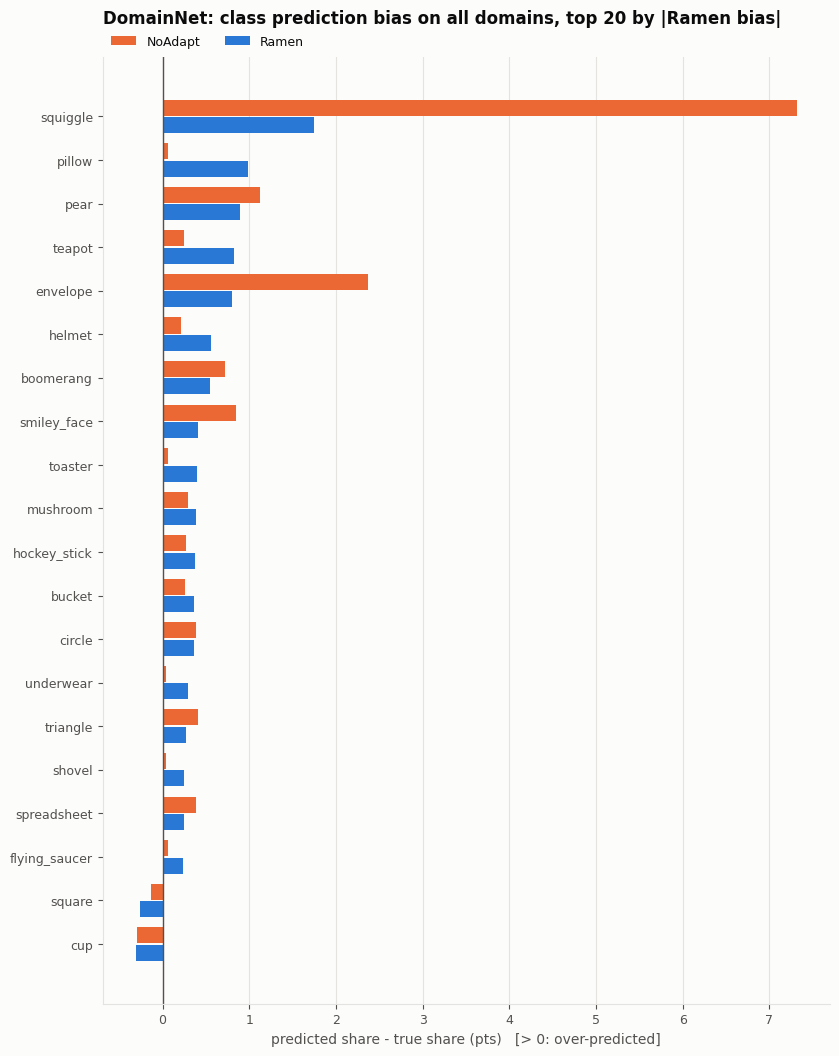

In [9]:
exp.plot_prediction_bias();

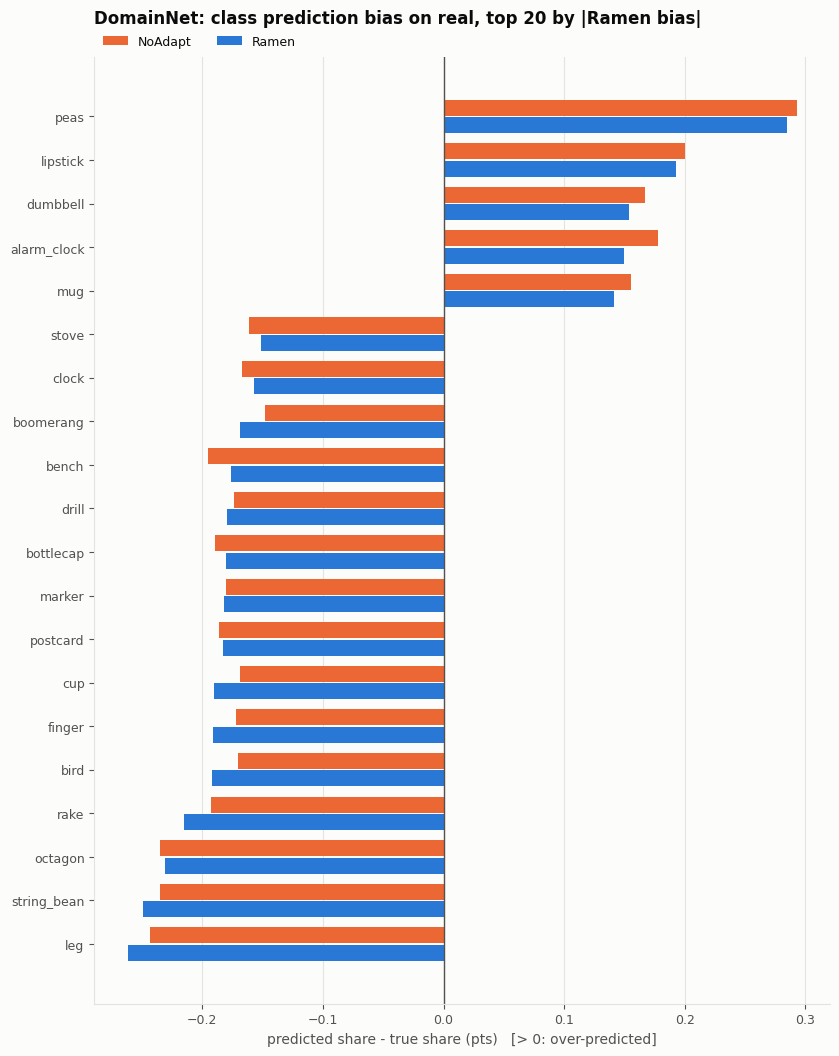

In [10]:
exp.plot_prediction_bias(domain=acc.drop('average')['delta'].idxmin());  # the domain where Ramen gains least

## 5. What gets confused with what
A 345×345 matrix is unreadable, so these are the most frequent `true -> predicted` errors, with each one's share of the true class.

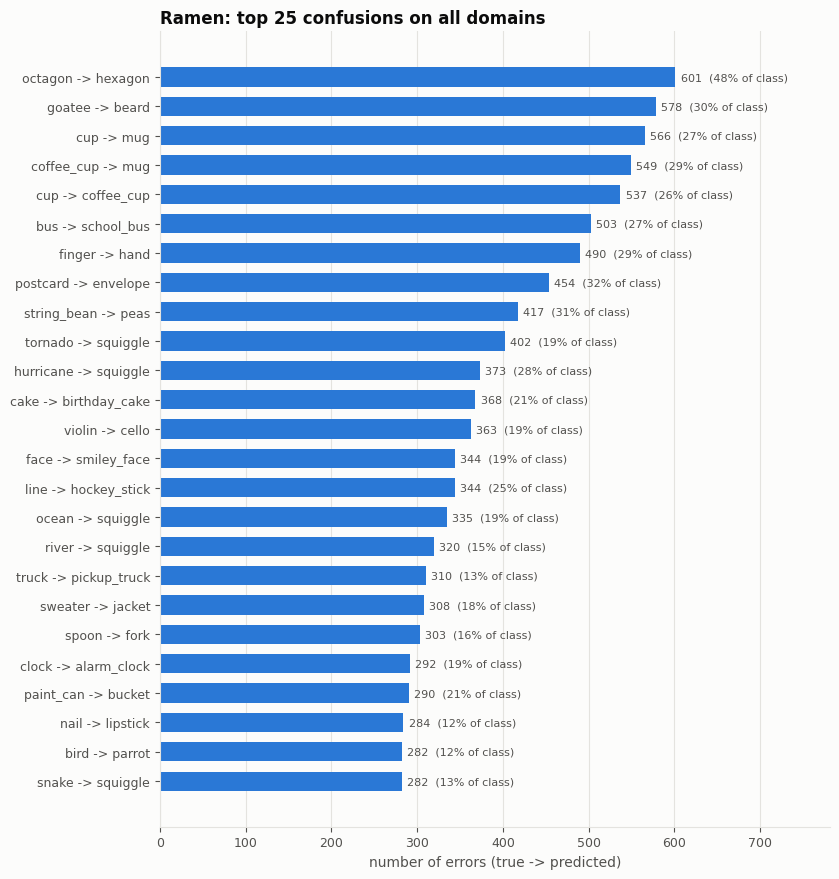

In [11]:
exp.plot_confusion();

worst domain for Ramen: quickdraw


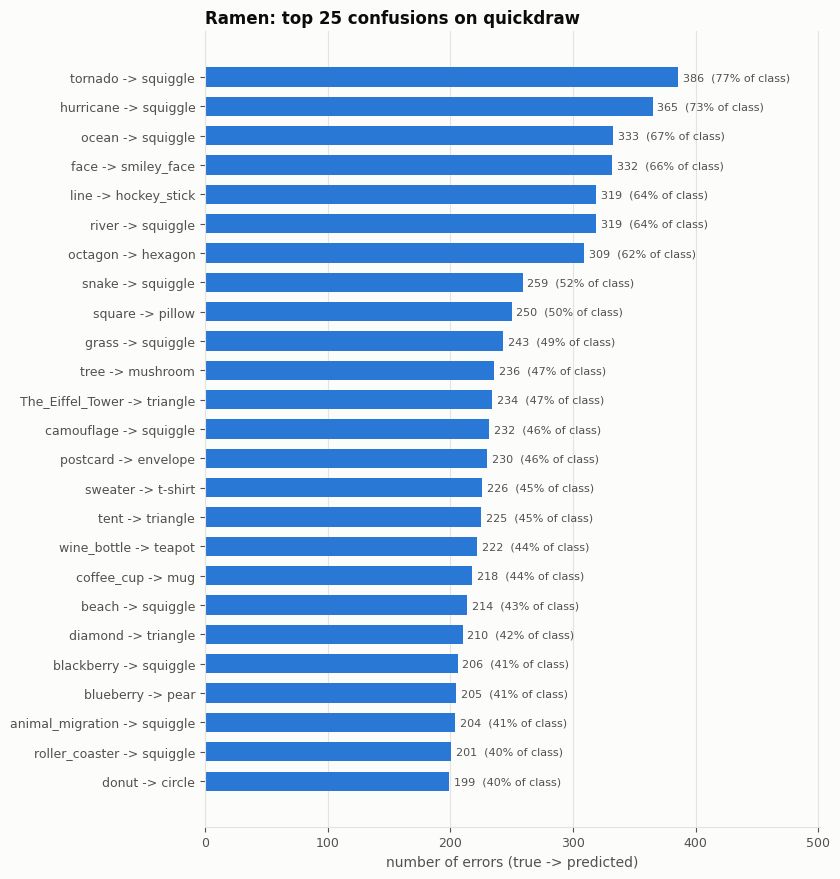

In [12]:
worst = acc.drop('average')['Ramen'].idxmin()
print('worst domain for Ramen:', worst)
exp.plot_confusion(domain=worst);

## 6. Does Ramen degrade over time?
Top panel: rolling accuracy along the stream. Bottom panel: rolling Ramen − NoAdapt gap. A gap that shrinks or turns red later in the stream points to cache staleness or error accumulation. The DomainNet stream (~596k samples) is far longer than CIFAR's 150k: Ramen's cache priorities are fp16 and overflow to inf after 65,520 samples, after which full queues freeze, so a late-stream decline here may come from that.

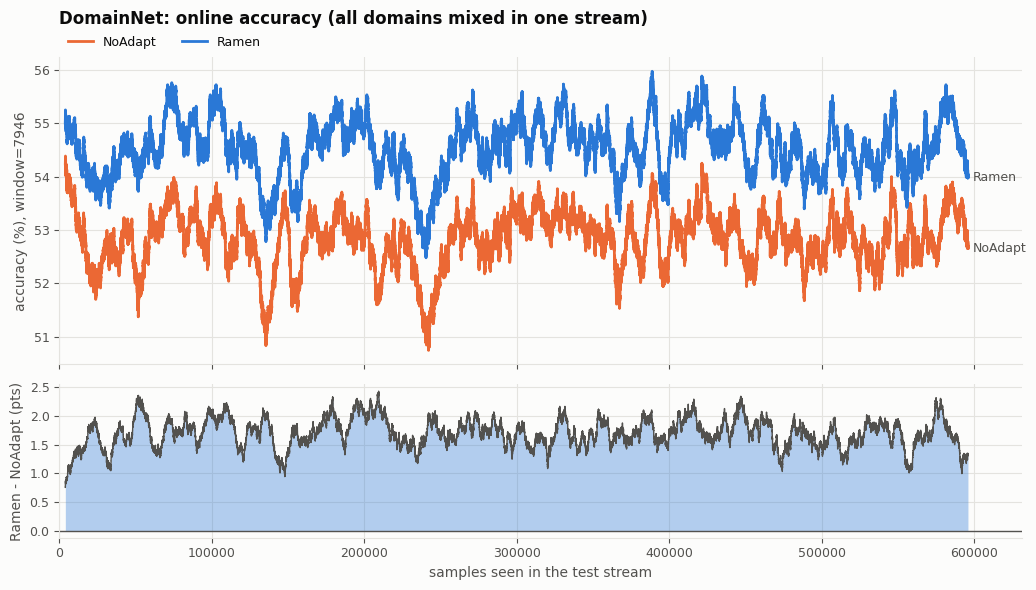

In [13]:
exp.plot_online_accuracy();

## 7. Calibration
Left: points below the diagonal mean the model is overconfident. Right: Ramen's confidence on wrong predictions. Errors made at high confidence are the most dangerous failures, because a confidence threshold won't catch them.

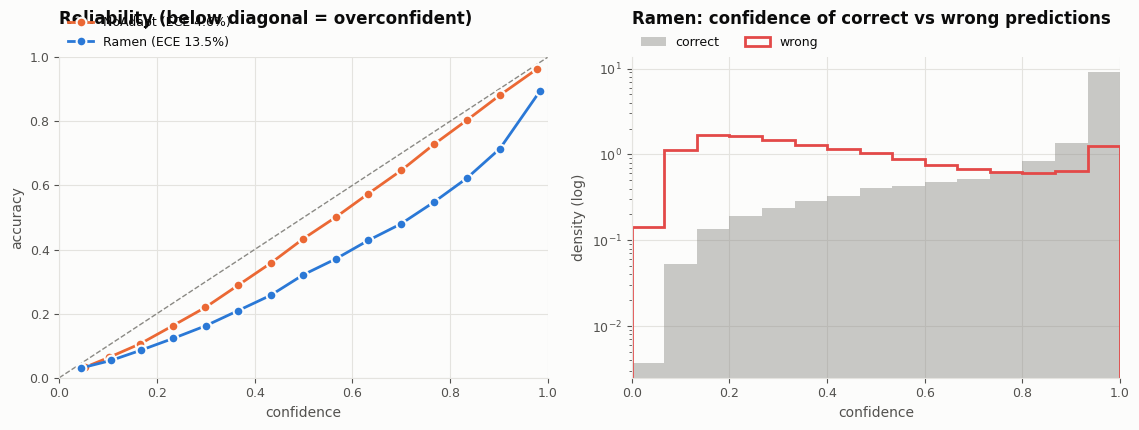

In [14]:
exp.plot_calibration();

## 8. Look at the failures
Images are sorted most-confident first. Captions show the domain, the true class, and Ramen's prediction with its confidence.
`kind`: `'broken'` (Ramen broke a correct zero-shot prediction), `'both wrong'`, `'fixed'`, or `'wrong'` (any Ramen error).

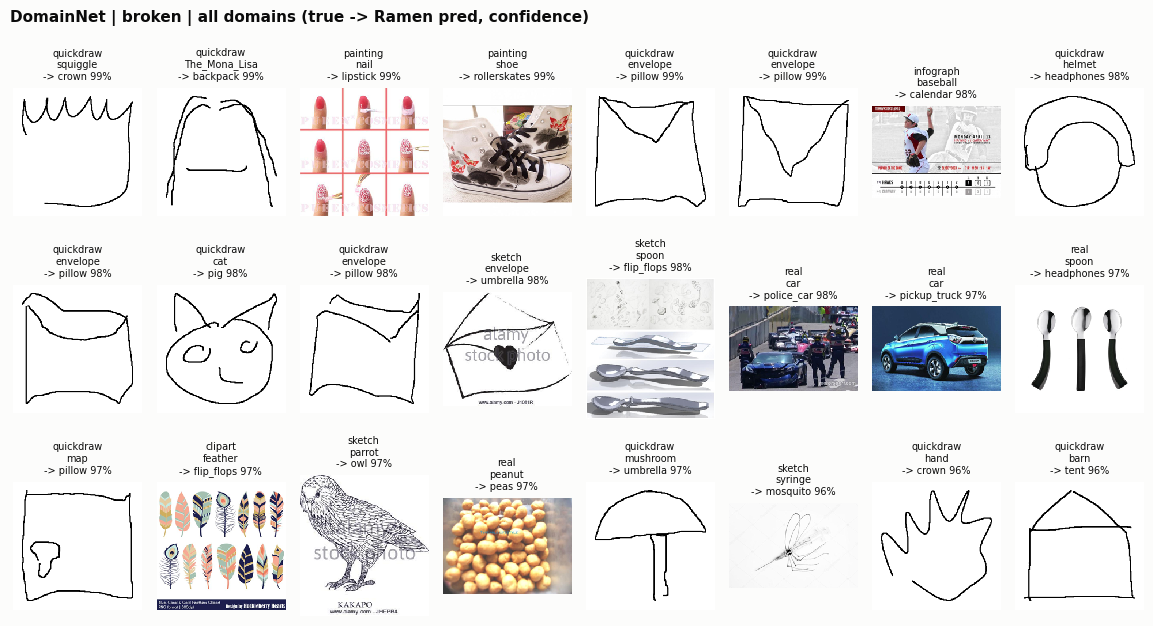

In [15]:
exp.show_failures(kind='broken', n=24);

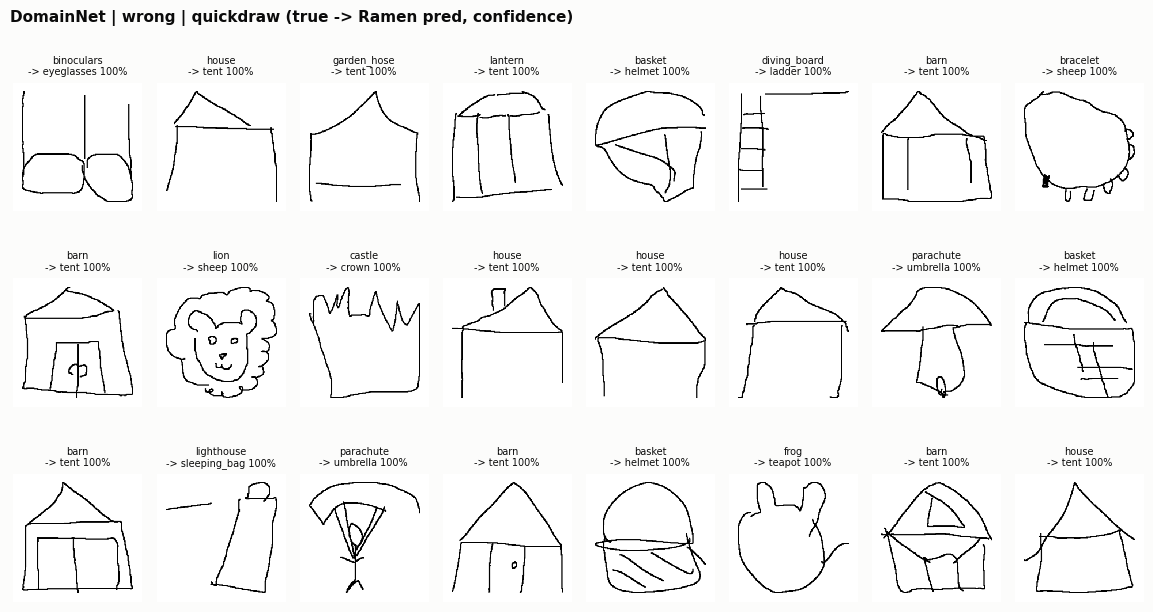

In [16]:
exp.show_failures(domain=worst, kind='wrong', n=24);

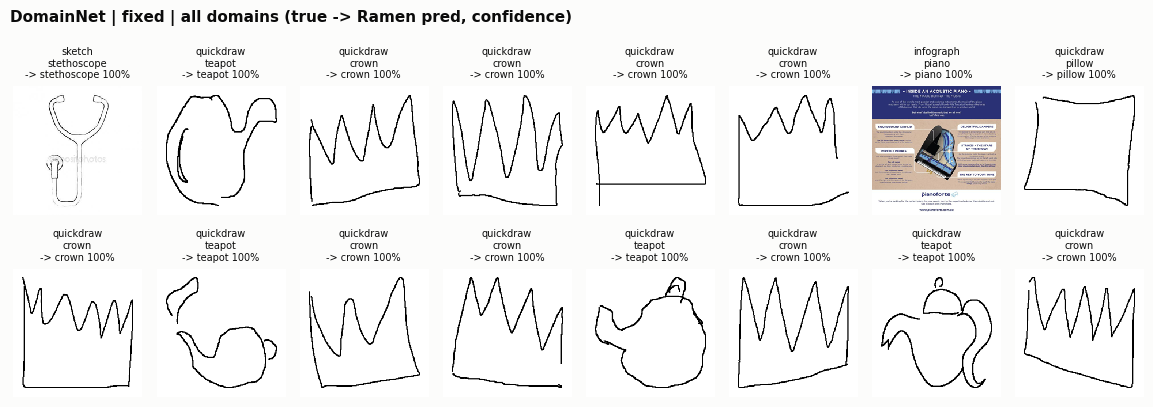

In [17]:
exp.show_failures(kind='fixed', n=16);

Images for the most confused pairs, one row per pair. A row labelled `true: A / Ramen: B` shows images whose true class is A that Ramen predicts as B. Each caption gives the domain, Ramen's confidence in B, and what NoAdapt did on the same image: `right` (it predicted A), `same error` (it also predicted B), or the other wrong class it picked.
`order='confident'` shows the errors Ramen is surest about first; `order='borderline'` shows the ones where it barely picked B (low confidence, so other classes were close behind).

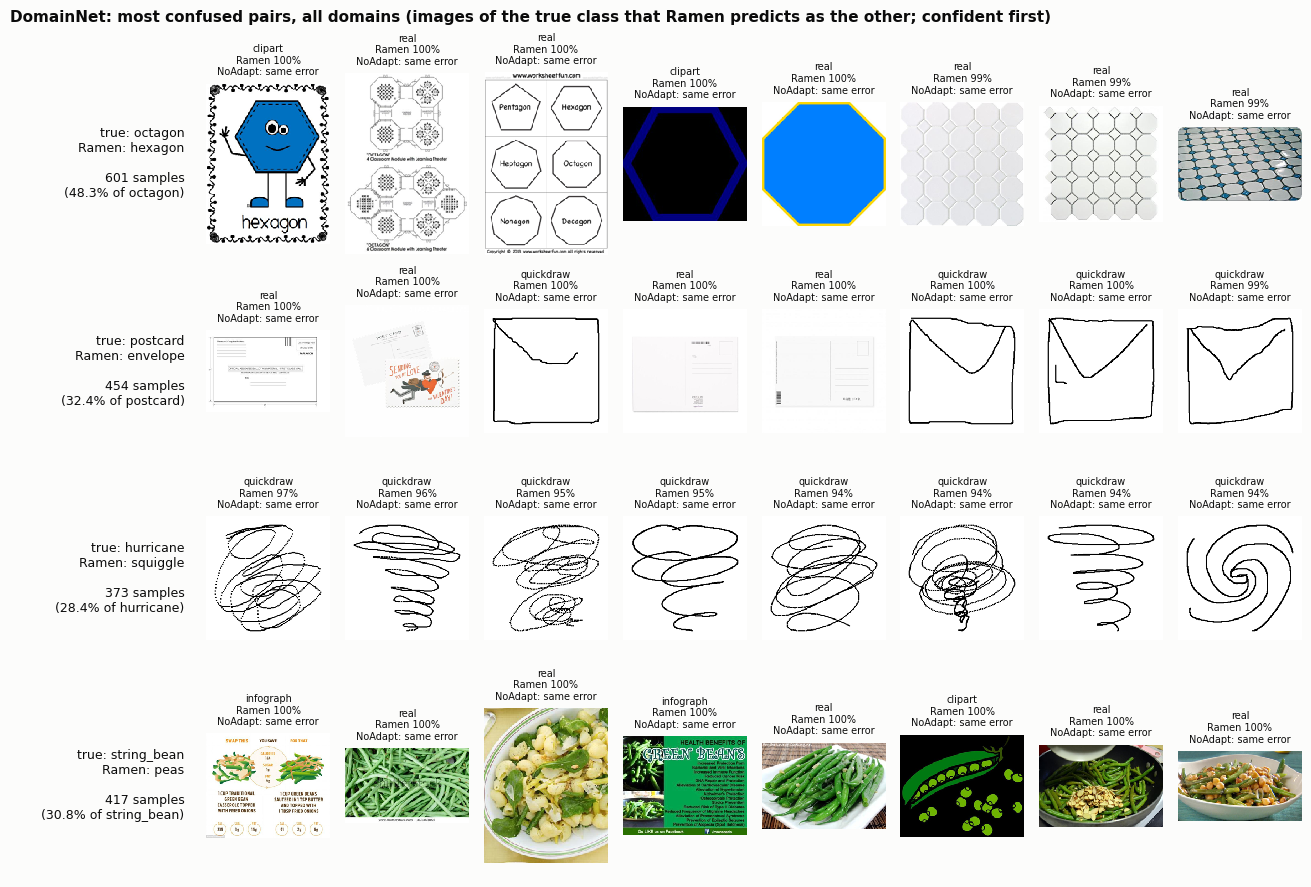

In [18]:
exp.show_confused_pairs(top_k=4, n=8);

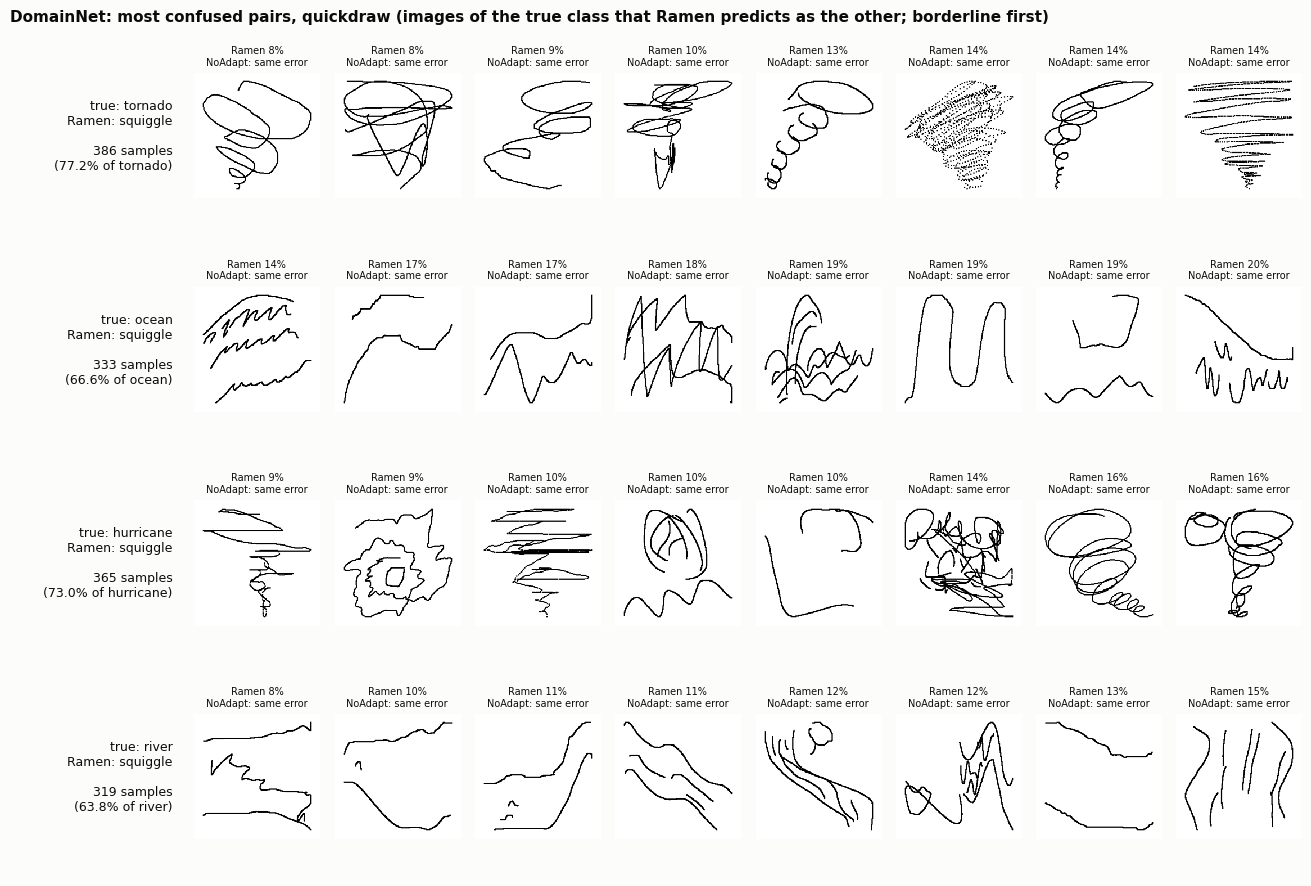

In [19]:
exp.show_confused_pairs(domain=worst, top_k=4, n=8, order='borderline');

## 9. Would "keep zero-shot when it is confident" help?
Post-hoc gate: use NoAdapt's prediction wherever its confidence is at least `tau`, and Ramen's elsewhere. This is exact for a gate that only skips a sample's own update, because the memory doesn't change. `oracle` is the ceiling for *any* per-sample choice between the two methods.

In [20]:
gate = exp.gate_sweep()
print(f"Ramen: {gate.attrs['Ramen']:.2f}   oracle (either right): {gate.attrs['oracle']:.2f}")
gate

Ramen: 54.52   oracle (either right): 56.25


,gated %,NoAdapt acc in gate,Ramen acc in gate,gated total acc,broken saved,fixed lost
tau,,,,,,
0.50,54.96,80.85,81.01,54.43,1562,2097
0.60,48.33,85.29,85.32,54.51,622,715
0.70,42.26,89.04,89.02,54.53,259,201
0.80,35.77,92.34,92.32,54.53,96,50
0.90,27.46,95.30,95.29,54.53,26,8
0.95,20.58,96.82,96.82,54.52,6,4
0.99,7.99,98.63,98.63,54.52,0,0


## 10. Would "don't adapt when zero-shot entropy is already low" help?
Same post-hoc gate as section 9, but the signal is zero-shot **entropy** instead of confidence: use NoAdapt's prediction wherever its entropy is at most `tau · ln C`, and Ramen's elsewhere. `ln C` is the largest possible entropy (all classes equally likely), so `tau` is a fraction of it and the same `tau` values work for any number of classes. `entropy threshold` is the cut-off in nats (`ln 345 ≈ 5.84` here). Low `tau` gates only the samples zero-shot is very sure about. (EATA uses the same scale, `0.4 · ln C`, for the opposite rule: it skips *high*-entropy samples.)
The columns mean the same as in section 9:
- `gated %`: share of samples kept at zero-shot.
- `broken saved`: gated samples where Ramen was wrong and zero-shot right.
- `fixed lost`: gated samples where Ramen was right and zero-shot wrong.
- Compare `gated total acc` with Ramen's accuracy printed above the table.

As in section 9, these accuracies are per image (Ramen 54.52), not the domain average (56.80): quickdraw is the largest and hardest domain, so it weighs more here.

In [4]:
entropy_gate = exp.entropy_gate_sweep()   # taus=(0.05, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6) by default
print(f"Ramen: {entropy_gate.attrs['Ramen']:.2f}   oracle (either right): {entropy_gate.attrs['oracle']:.2f}")
entropy_gate

Ramen: 54.52   oracle (either right): 56.25


,entropy threshold,gated %,NoAdapt acc in gate,Ramen acc in gate,gated total acc,broken saved,fixed lost
tau,,,,,,,
0.05,0.292,19.32,96.96,96.96,54.52,5,4
0.10,0.584,27.88,95.00,94.99,54.53,36,18
0.20,1.169,40.34,89.29,89.36,54.50,880,1050
0.30,1.753,49.71,83.96,84.14,54.43,2270,2804
0.40,2.337,58.04,78.55,78.93,54.30,3728,5040
0.50,2.922,66.77,72.64,73.34,54.06,5344,8118
0.60,3.506,77.02,65.80,66.89,53.69,7229,12220
